# Separating signal eigenvalues from noise

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. Gaussian simulations use Cholesky factors. NERCOME uses saved Xoshiro row permutations with the same split fraction and split count. Saved draws, covariances, and portfolio weights allow the calculations to be repeated across languages.

The Marcenko-Pastur density describes the limiting eigenvalue spread of a covariance matrix formed from independent noise:

$$
f(\lambda)=\frac{q}{2\pi\sigma^2\lambda}
\sqrt{(\lambda_+-\lambda)(\lambda-\lambda_-)},
\qquad
\lambda_{\pm}=\sigma^2\left(1\pm q^{-1/2}\right)^2,
\qquad q=\frac{T}{N}>1.
$$

Here, $\lambda$ is an eigenvalue; $f(\lambda)$ is its density; $\sigma^2$ is the fitted noise variance. $\lambda_-$ and $\lambda_+$ are the lower and upper noise boundaries; $T$ is observation count; $N$ is variable count; $q=T/N.$ $\pi$ is the circle constant, and the formula applies on $[\lambda_-,\lambda_+]$ under the stated large-sample noise model.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("10_covariance_denoising");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end


box_summary! (generic function with 1 method)

## Fitting a Noise Boundary

In [2]:
snapshot = industry_returns[findall(<=(Date(2024,12,31)),industry_dates)[end-124:end],:]
observation_count,portfolio_count = size(snapshot)
q_ratio,bandwidth = observation_count/portfolio_count,.05
sample_covariance = cov(snapshot)
sample_standard_deviation = sqrt.(diag(sample_covariance))
fitted = covariance_fit(sample_covariance,q_ratio,bandwidth)
sample_correlation,raw_eigenvalues,raw_eigenvectors = fitted.correlation,fitted.values,fitted.vectors
lambda_max,fitted_variance,signal_count = fitted.cutoff,fitted.variance,fitted.factors
lambda_min = fitted_variance*(1-q_ratio^(-.5))^2
noise_count = portfolio_count-signal_count
mp_fit_summary = DataFrame("Quantity"=>["Observations","Portfolios","Observation to portfolio ratio","Kernel bandwidth","Fitted noise variance","Lower noise boundary","Upper noise boundary","Signal eigenvalues","Noise eigenvalues"],"Value"=>[observation_count,portfolio_count,q_ratio,bandwidth,fitted_variance,lambda_min,lambda_max,signal_count,noise_count])
save_table(mp_fit_summary,paths,"mp_fit_summary";caption="Fitted random-matrix noise boundary for the 125-day public window.",label="tab:chapter9-mp-fit")
density_grid,theoretical_density = marcenko_pastur_pdf(fitted_variance,q_ratio;num_points=500)
empirical_density = exp.(score_samples(fit_kde(raw_eigenvalues;bandwidth),density_grid))
save_data(DataFrame(eigenvalue=density_grid,theoretical=theoretical_density,empirical=empirical_density),paths,"mp_density")
save_data(matrix_frame(snapshot),paths,"snapshot_returns")
save_data(DataFrame(direction=1:49,eigenvalue=raw_eigenvalues),paths,"snapshot_eigenvalues");
save_data(DataFrame(variance=[fitted.variance],cutoff=[fitted.cutoff],factors=[fitted.factors],converged=[fitted.converged],latent_variance=[fitted.latent_variance],objective=[fitted.objective],iterations=[fitted.iterations]),paths,"snapshot_noise_fit");


Row,Quantity,Value
,String,Float64
1,Observations,125.0
2,Portfolios,49.0
3,Observation to portfolio ratio,2.55102
4,Kernel bandwidth,0.05
5,Fitted noise variance,0.500786
6,Lower noise boundary,0.0700109
7,Upper noise boundary,1.32418
8,Signal eigenvalues,5.0
9,Noise eigenvalues,44.0


## Comparing two covariance cleaning methods

Constant residual cleaning keeps the leading signal eigenvalues and replaces every noise eigenvalue by their average:

$$
\widetilde\lambda_j=
\begin{cases}
\lambda_j,&j\leq K,\\
\displaystyle\frac{1}{N-K}\sum_{k=K+1}^{N}\lambda_k,&j>K,
\end{cases}
\qquad
\widetilde C_{\mathrm{const}}=Q\widetilde\Lambda Q^{\mathsf T}.
$$

Here, $\lambda_j$ is ordered eigenvalue $j$; $K$ is the number above the fitted noise boundary; $N$ is matrix size. $\widetilde\lambda_j$ is a cleaned eigenvalue; $Q$ contains the original eigenvectors; $\widetilde\Lambda$ contains cleaned eigenvalues. $\widetilde C_{\mathrm{const}}$ is the reconstructed matrix, rescaled afterward to unit diagonal.

Targeted shrinkage keeps the signal part and reduces only the off-diagonal contribution assigned to noise:

$$
\widetilde C_{\alpha}
=Q_L\Lambda_LQ_L^{\mathsf T}
+\alpha Q_R\Lambda_RQ_R^{\mathsf T}
+(1-\alpha)\operatorname{diag}\!\left(Q_R\Lambda_RQ_R^{\mathsf T}\right),
\qquad 0\leq\alpha\leq1.
$$

Here, $Q_L,\Lambda_L$ contain the leading signal eigenvectors and eigenvalues; $Q_R,\Lambda_R$ contain the remaining noise part. $\operatorname{diag}(A)$ keeps only the diagonal of $A$; $\alpha$ is the retained share of the noise off-diagonal contribution. $\widetilde C_{\alpha}$ is the cleaned matrix; $\alpha=0$ gives full targeted shrinkage and $\alpha=1$ returns the original matrix.

Row,Method,Smallest eigenvalue,Largest eigenvalue,Condition number,Trace,Change from sample
,String,Float64,Float64,Float64,Float64,Float64
1,Sample,0.0247245,21.9912,889.448,49.0,0.0
2,Constant residual,0.292923,21.2472,72.5351,49.0,2.77565
3,"Targeted, alpha 0",0.111183,22.2718,200.317,49.0,2.07329
4,"Targeted, alpha 0.5",0.0834562,22.1313,265.185,49.0,1.03664


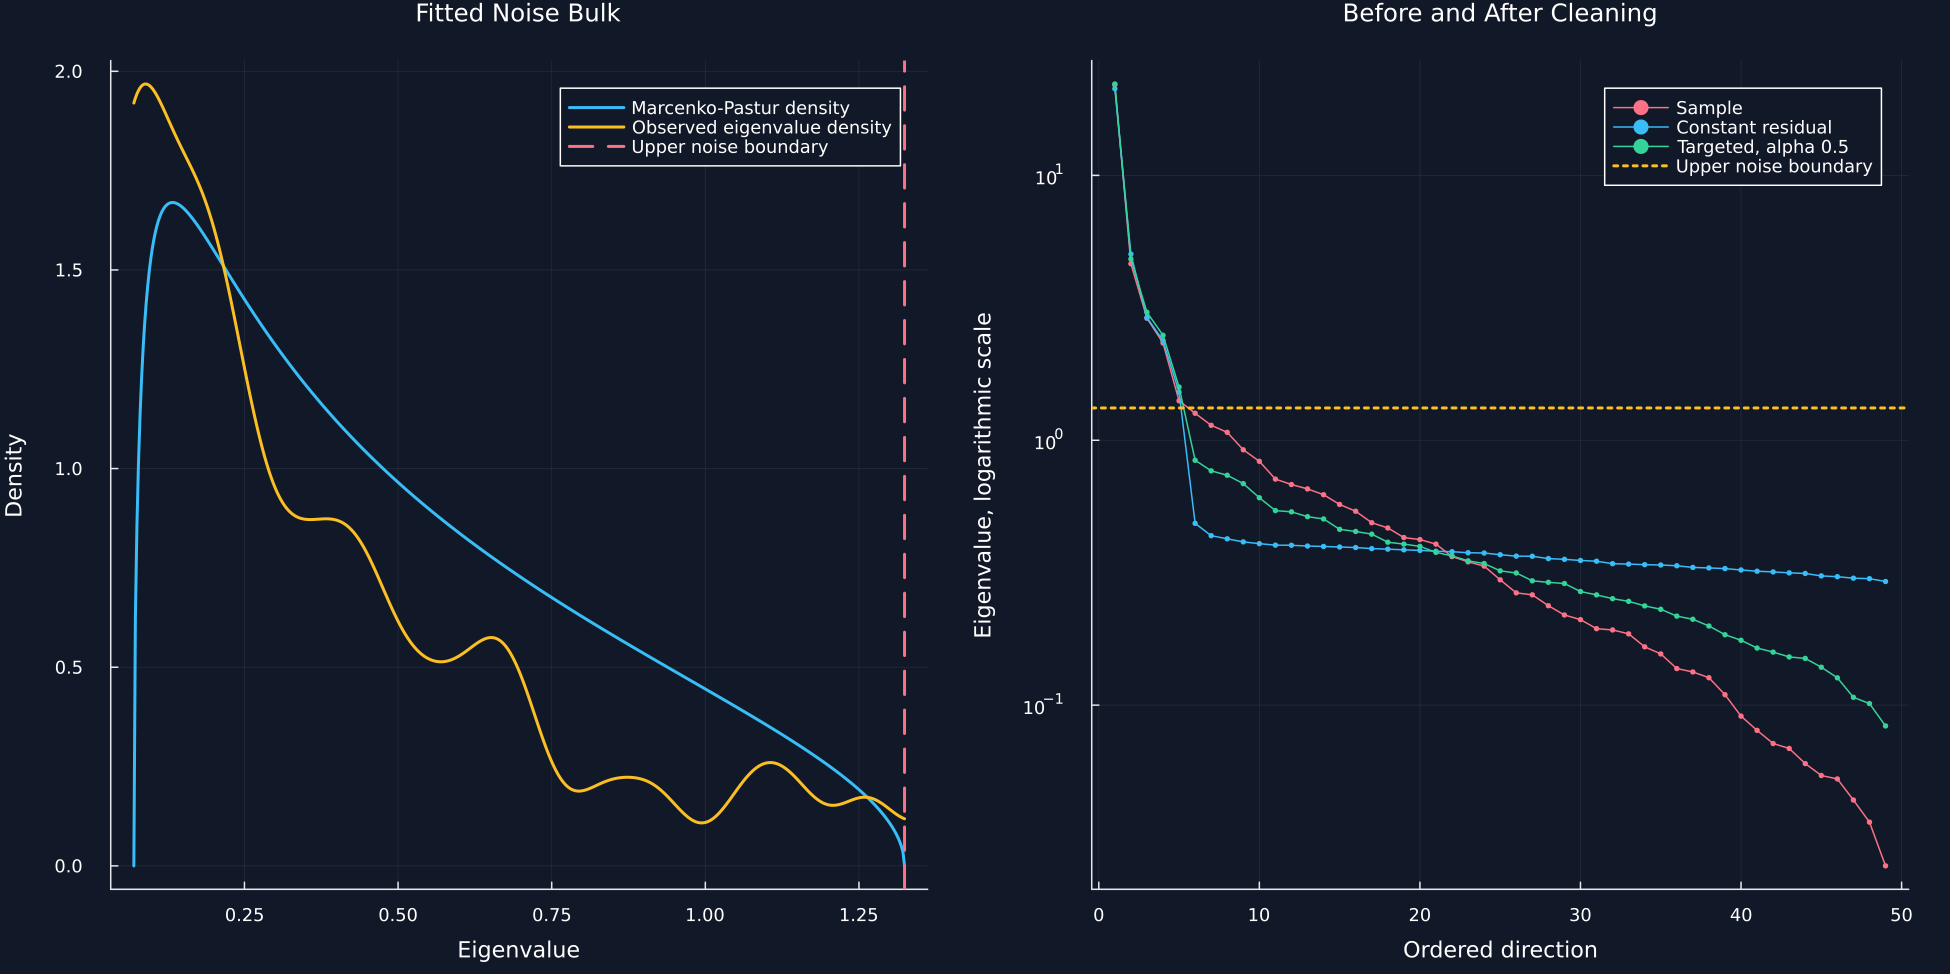

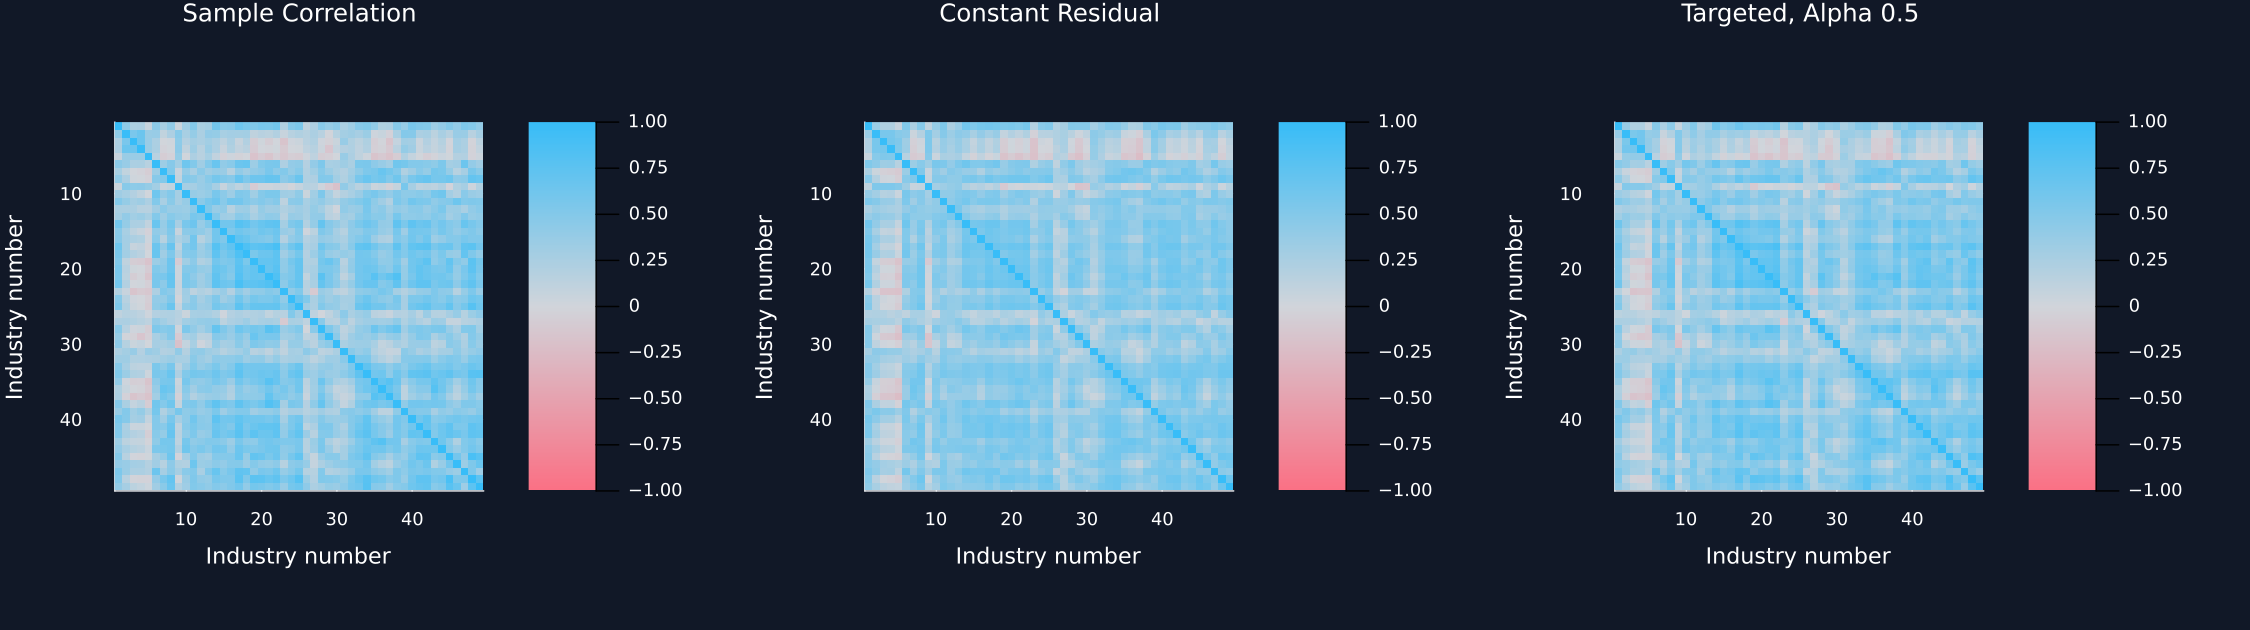

In [3]:
constant_correlation = denoised_corr(raw_eigenvalues,raw_eigenvectors,signal_count)
constant_covariance = corr_to_cov(constant_correlation,sample_standard_deviation)
targeted_full_correlation = denoised_corr2(Diagonal(raw_eigenvalues),raw_eigenvectors,signal_count;alpha=0.)
targeted_half_correlation = denoised_corr2(Diagonal(raw_eigenvalues),raw_eigenvectors,signal_count;alpha=.5)
targeted_full_covariance = corr_to_cov(targeted_full_correlation,sample_standard_deviation)
targeted_half_covariance = corr_to_cov(targeted_half_correlation,sample_standard_deviation)
method_covariances = ["Sample"=>sample_covariance,"Constant residual"=>constant_covariance,"Targeted, alpha 0"=>targeted_full_covariance,"Targeted, alpha 0.5"=>targeted_half_covariance]
matrix_rows = NamedTuple[]
saved_matrices = DataFrame()
for (method,covariance) in method_covariances
    current_correlation = cov_to_corr(covariance)
    values = eigvals(Symmetric(current_correlation))
    push!(matrix_rows,(method=method,smallest=first(values),largest=last(values),condition=last(values)/first(values),trace=tr(current_correlation),change=norm(current_correlation-sample_correlation)))
    append!(saved_matrices,matrix_frame(covariance;method);cols=:union)
end
denoising_matrix_summary = DataFrame(matrix_rows)
rename!(denoising_matrix_summary,["Method","Smallest eigenvalue","Largest eigenvalue","Condition number","Trace","Change from sample"])
save_table(denoising_matrix_summary,paths,"denoising_matrix_summary";caption="Spectral properties of the public sample and three cleaned estimates.",label="tab:chapter9-denoising-matrix")
save_data(saved_matrices,paths,"snapshot_covariances")
p1 = plot(density_grid,theoretical_density;color=palette.cyan,label="Marcenko-Pastur density",title="Fitted Noise Bulk",xlabel="Eigenvalue",ylabel="Density",legend=:topright)
plot!(p1,density_grid,empirical_density;color=palette.amber,label="Observed eigenvalue density")
vline!(p1,[lambda_max];color=palette.rose,linestyle=:dash,label="Upper noise boundary")
p2 = plot(;yscale=:log10,title="Before and After Cleaning",xlabel="Ordered direction",ylabel="Eigenvalue, logarithmic scale",legend=:topright)
for (method,covariance,color) in [("Sample",sample_covariance,palette.rose),("Constant residual",constant_covariance,palette.cyan),("Targeted, alpha 0.5",targeted_half_covariance,palette.green)]
    plot!(p2,1:49,reverse(eigvals(Symmetric(cov_to_corr(covariance))));color,label=method,marker=:circle,markersize=2,markerstrokewidth=0,linewidth=1)
end
hline!(p2,[lambda_max];color=palette.amber,linestyle=:dot,label="Upper noise boundary")
save_figure(plot(p1,p2;layout=(1,2),size=(1300,650)),paths,"mp_noise_bulk")
panels = []
for (matrix,title) in [(sample_correlation,"Sample Correlation"),(constant_correlation,"Constant Residual"),(targeted_half_correlation,"Targeted, Alpha 0.5")]
    push!(panels,heatmap(1:49,1:49,matrix;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),yflip=true,xlims=(.5,49.5),ylims=(.5,49.5),widen=false,aspect_ratio=:equal,title,xlabel="Industry number",ylabel="Industry number",left_margin=7Plots.mm))
end
save_figure(plot(panels...;layout=(1,3),size=(1500,420)),paths,"denoised_correlation_matrices")


## Error with Known Truth

Relative Frobenius error compares an estimated covariance with a known population covariance on a common scale:

$$
\mathcal E(\widehat\Sigma,\Sigma_0)
=\frac{\lVert\widehat\Sigma-\Sigma_0\rVert_F}{\lVert\Sigma_0\rVert_F}.
$$

Here, $\widehat\Sigma$ is an estimated covariance; $\Sigma_0$ is the covariance used to generate the simulated returns. $\lVert A\rVert_F=\sqrt{\sum_{i,j}A_{ij}^2}$ is the Frobenius norm; $\mathcal E$ is dimensionless relative error.

In [4]:
block_size,block_count,block_correlation = 7,7,.35
block = (1-block_correlation)*Matrix{Float64}(I,7,7)+block_correlation*ones(7,7)
true_correlation = kron(Matrix{Float64}(I,7,7),block)
true_standard_deviation = vec(std(industry_returns;dims=1))
true_covariance = corr_to_cov(true_correlation,true_standard_deviation)
true_cholesky = cholesky(Symmetric(true_covariance)).L
simulation_rows,simulation_fit_rows = NamedTuple[],NamedTuple[]
simulation_draws,simulation_covariances = DataFrame(),DataFrame()
repetition_count = 40
for repetition in 0:repetition_count-1
    primitive = randn(Xoshiro(9000+repetition),observation_count,portfolio_count)
    simulated_returns = primitive*transpose(true_cholesky)
    simulated_sample = cov(simulated_returns)
    simulated_clean = denoise_cov(simulated_sample,q_ratio;bandwidth)
    current = covariance_fit(simulated_sample,q_ratio,bandwidth)
    simulated_targeted_corr = denoised_corr2(Diagonal(current.values),current.vectors,current.factors;alpha=.5)
    simulated_targeted = corr_to_cov(simulated_targeted_corr,sqrt.(diag(simulated_sample)))
    append!(simulation_draws,matrix_frame(primitive;repetition=repetition+1,seed=9000+repetition);cols=:union)
    push!(simulation_fit_rows,(repetition=repetition+1,cutoff=current.cutoff,variance=current.variance,factors=current.factors,converged=current.converged,latent_variance=current.latent_variance,objective=current.objective,iterations=current.iterations))
    for (method,estimate) in [("Sample",simulated_sample),("Constant residual",simulated_clean),("Targeted, alpha 0.5",simulated_targeted)]
        push!(simulation_rows,(repetition=repetition+1,method=method,error=norm(estimate-true_covariance)/norm(true_covariance),condition=cond(cov_to_corr(estimate))))
        append!(simulation_covariances,matrix_frame(estimate;repetition=repetition+1,method);cols=:union)
    end
end
simulation_results = DataFrame(simulation_rows)
rename!(simulation_results,["Repetition","Method","Relative covariance error","Condition number"])
raw_errors = simulation_results[simulation_results.Method.=="Sample","Relative covariance error"]
summary_rows = NamedTuple[]
for method in ["Sample","Constant residual","Targeted, alpha 0.5"]
    group = simulation_results[simulation_results.Method.==method,:]
    errors = group[!,"Relative covariance error"]
    push!(summary_rows,(method=method,mean=mean(errors),median=median(errors),std=std(errors),condition=mean(group[!,"Condition number"]),win=method=="Sample" ? NaN : mean(errors.<raw_errors)))
end
known_truth_denoising_summary = DataFrame(summary_rows)
rename!(known_truth_denoising_summary,["Method","Mean relative error","Median relative error","Error standard deviation","Mean condition number","Share beating sample"])
save_table(known_truth_denoising_summary,paths,"known_truth_denoising_summary";caption="Known-truth covariance error across forty fixed-seed repetitions.",label="tab:chapter9-known-truth")
save_data(simulation_results,paths,"known_truth_denoising_runs")
save_data(simulation_draws,paths,"known_truth_gaussian_draws")
save_data(simulation_covariances,paths,"known_truth_covariances")
save_data(DataFrame(simulation_fit_rows),paths,"known_truth_noise_fits")
save_data(matrix_frame(true_covariance),paths,"known_truth_covariance");


Row,Method,Mean relative error,Median relative error,Error standard deviation,Mean condition number,Share beating sample
,String,Float64,Float64,Float64,Float64,Float64
1,Sample,0.441918,0.439563,0.0245523,39.9022,NaN
2,Constant residual,0.368303,0.36459,0.0260045,8.03357,1.0
3,"Targeted, alpha 0.5",0.427476,0.425076,0.030539,16.0101,0.95


## Slowly Decaying Spectrum

Each repetition learns directions from one sample part, measures their variances on the other part, and the final estimate averages those repetitions:

$$
\widehat\Sigma_b
=P_b\operatorname{diag}\!\left(P_b^{\mathsf T}S_{2,b}P_b\right)P_b^{\mathsf T},
\qquad
\widehat\Sigma_{\mathrm N}=\frac{1}{B}\sum_{b=1}^{B}\widehat\Sigma_b.
$$

Here, $b$ indexes a sample split; $P_b$ contains eigenvectors from the first part; $S_{2,b}$ is covariance from the second part. $\operatorname{diag}(P_b^{\mathsf T}S_{2,b}P_b)$ keeps the measured variance along each direction; $B$ is the number of splits; $\widehat\Sigma_{\mathrm N}$ is the averaged estimate.

Weights are chosen from estimate $m$, then their variance is measured under the known covariance that generated the returns:

$$
V_m=w_m^{\mathsf T}\Sigma_0w_m,
\qquad
w_m=\frac{\widehat\Sigma_m^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\widehat\Sigma_m^{-1}\mathbf 1}.
$$

Here, $m$ names a covariance estimate; $\widehat\Sigma_m$ is that estimate; $w_m$ is its minimum-variance weight vector. $\Sigma_0$ is the known covariance; $V_m$ is realized true variance; $\mathbf 1$ is a vector of ones; $\mathsf T$ denotes transpose.

Row,Method,Mean relative covariance error,Median relative covariance error,Mean condition number,Mean realized true variance,Median realized true variance
,String,Float64,Float64,Float64,Float64,Float64
1,NERCOME split average,0.434151,0.434185,16.4502,0.00932018,0.00902496
2,Random-matrix clipping,0.515201,0.514183,15.7877,0.012515,0.0120935
3,Raw sample,0.461608,0.448333,111.905,0.0102213,0.00997304


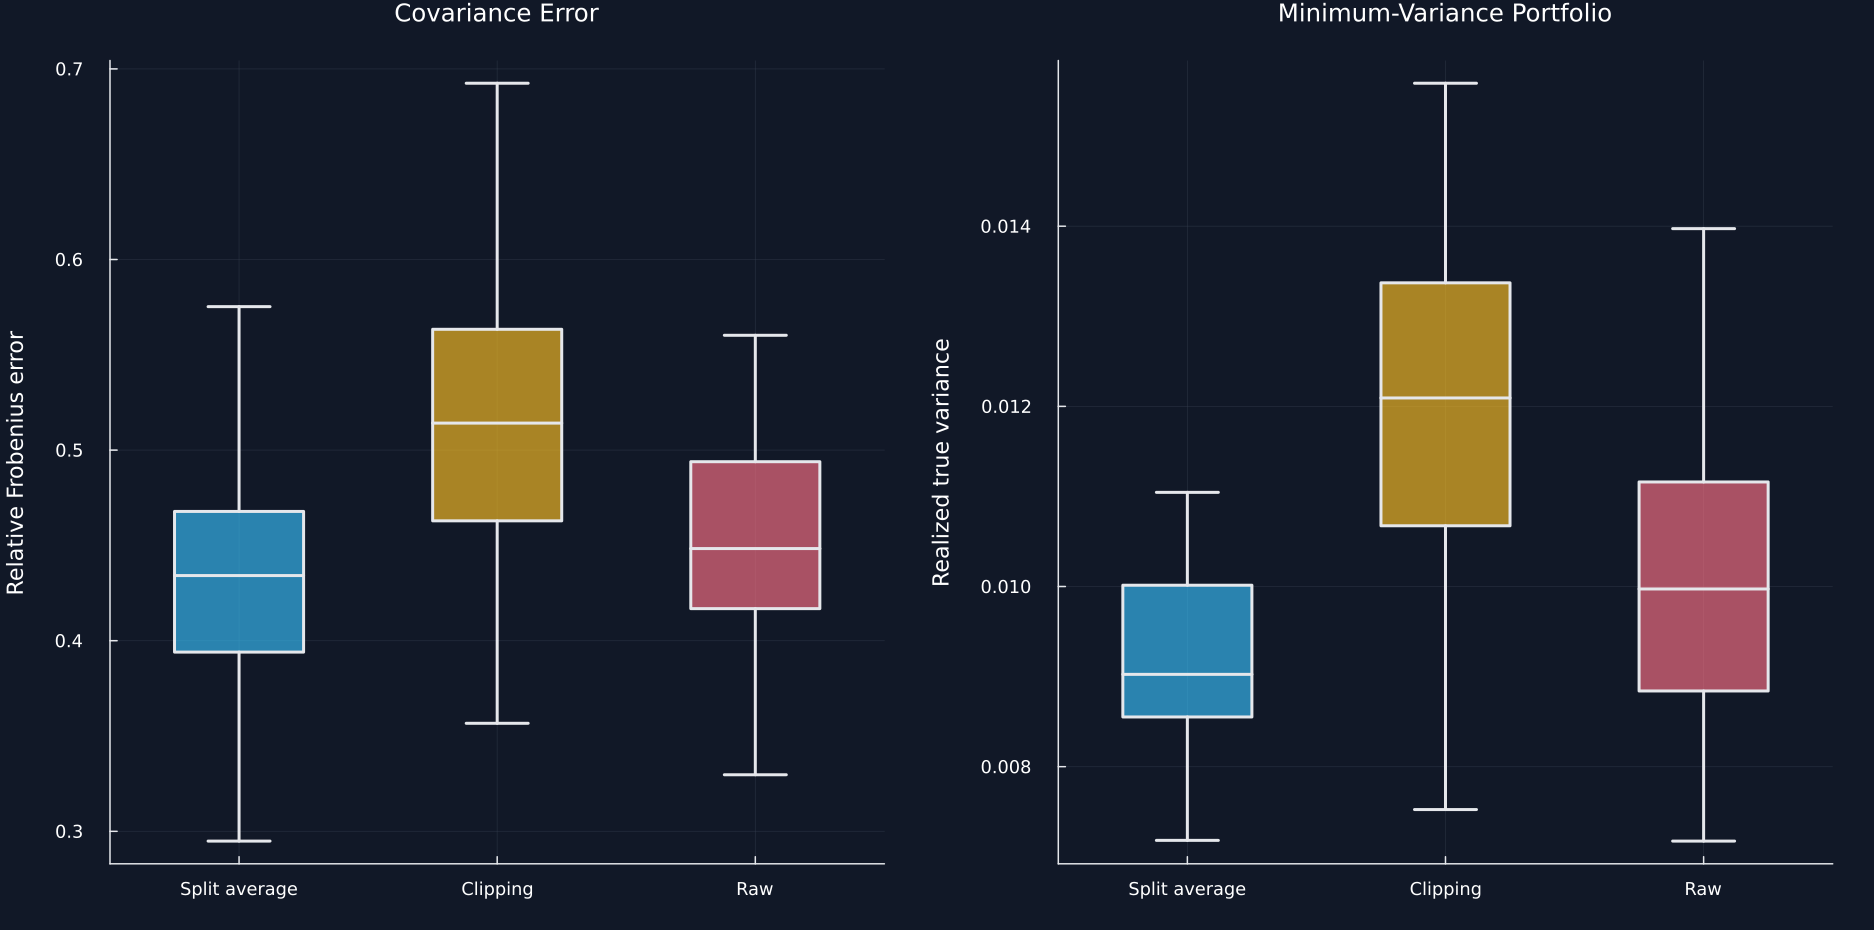

In [5]:
no_gap_dimension,no_gap_observations = 12,30
no_gap_eigenvalues = [1.4^(-index) for index in 0:11]
no_gap_generator = Xoshiro(123)
direction_draws = randn(no_gap_generator,12,12)
no_gap_directions = Matrix(qr(direction_draws).Q)
no_gap_truth = no_gap_directions*Diagonal(no_gap_eigenvalues)*transpose(no_gap_directions)
no_gap_truth = (no_gap_truth+transpose(no_gap_truth))/2
no_gap_cholesky = cholesky(Symmetric(no_gap_truth)).L
no_gap_rows,no_gap_fit_rows = NamedTuple[],NamedTuple[]
no_gap_draws,no_gap_permutations,no_gap_covariances = DataFrame(),DataFrame(),DataFrame()
for repetition in 0:39
    primitive = randn(no_gap_generator,no_gap_dimension,no_gap_observations)
    simulated_returns = Matrix(transpose(no_gap_cholesky*primitive))
    split_generator = Xoshiro(repetition)
    permutations = reduce(vcat,[transpose(randperm(split_generator,no_gap_observations)) for _ in 1:100])
    sample_estimate = cov(simulated_returns)
    nercome_estimate = nercome_denoised_covariance(simulated_returns;n_splits=100,random_state=repetition,permutations)
    clipping_estimate = denoise_cov(sample_estimate,no_gap_observations/no_gap_dimension;bandwidth=.01)
    current = covariance_fit(sample_estimate,no_gap_observations/no_gap_dimension,.01)
    push!(no_gap_fit_rows,(repetition=repetition+1,cutoff=current.cutoff,variance=current.variance,factors=current.factors,converged=current.converged,latent_variance=current.latent_variance,objective=current.objective,iterations=current.iterations))
    append!(no_gap_draws,matrix_frame(Matrix(transpose(primitive));repetition=repetition+1);cols=:union)
    append!(no_gap_permutations,matrix_frame(permutations;repetition=repetition+1,seed=repetition);cols=:union)
    for (method,estimate) in [("NERCOME split average",nercome_estimate),("Random-matrix clipping",clipping_estimate),("Raw sample",sample_estimate)]
        weights = optimal_portfolio(estimate)
        push!(no_gap_rows,(repetition=repetition+1,method=method,error=norm(estimate-no_gap_truth)/norm(no_gap_truth),condition=cond(estimate),variance=dot(weights,no_gap_truth*weights)))
        append!(no_gap_covariances,matrix_frame(estimate;repetition=repetition+1,method);cols=:union)
    end
end
no_gap_denoising_runs = DataFrame(no_gap_rows)
rename!(no_gap_denoising_runs,["Repetition","Method","Relative covariance error","Condition number","Realized true variance"])
no_gap_summary_rows = NamedTuple[]
no_gap_methods = ["NERCOME split average","Random-matrix clipping","Raw sample"]
for method in no_gap_methods
    group = no_gap_denoising_runs[no_gap_denoising_runs.Method.==method,:]
    push!(no_gap_summary_rows,(method=method,error_mean=mean(group[!,"Relative covariance error"]),error_median=median(group[!,"Relative covariance error"]),condition=mean(group[!,"Condition number"]),variance_mean=mean(group[!,"Realized true variance"]),variance_median=median(group[!,"Realized true variance"])))
end
no_gap_denoising_summary = DataFrame(no_gap_summary_rows)
rename!(no_gap_denoising_summary,["Method","Mean relative covariance error","Median relative covariance error","Mean condition number","Mean realized true variance","Median realized true variance"])
save_table(no_gap_denoising_summary,paths,"no_gap_denoising_summary";caption="Covariance and portfolio error for a slowly decaying known spectrum.",label="tab:chapter9-no-gap-denoising")
save_data(no_gap_denoising_runs,paths,"no_gap_denoising_runs")
save_data(no_gap_draws,paths,"no_gap_gaussian_draws")
save_data(no_gap_permutations,paths,"no_gap_permutations")
save_data(no_gap_covariances,paths,"no_gap_covariances")
save_data(DataFrame(no_gap_fit_rows),paths,"no_gap_noise_fits")
save_data(matrix_frame(direction_draws),paths,"no_gap_direction_draws")
save_data(matrix_frame(no_gap_truth),paths,"no_gap_truth")
no_gap_colors = [palette.cyan,palette.amber,palette.rose]
p1 = plot(;title="Covariance Error",ylabel="Relative Frobenius error",xticks=(1:3,["Split average","Clipping","Raw"]),xlims=(.5,3.5),legend=false)
p2 = plot(;title="Minimum-Variance Portfolio",ylabel="Realized true variance",xticks=(1:3,["Split average","Clipping","Raw"]),xlims=(.5,3.5),legend=false)
box_summary!(p1,[no_gap_denoising_runs[no_gap_denoising_runs.Method.==method,"Relative covariance error"] for method in no_gap_methods],no_gap_colors)
box_summary!(p2,[no_gap_denoising_runs[no_gap_denoising_runs.Method.==method,"Realized true variance"] for method in no_gap_methods],no_gap_colors)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,620)),paths,"no_gap_denoising")


## Tests

In [6]:
@assert size(snapshot)==(125,49)
@assert q_ratio>1
@assert 0<fitted_variance<1
@assert 0<lambda_min<lambda_max
@assert signal_count+noise_count==49
@assert signal_count>=1
@assert constant_correlation≈transpose(constant_correlation)
@assert diag(constant_correlation)≈ones(49)
@assert diag(targeted_full_correlation)≈ones(49)
@assert diag(targeted_half_correlation)≈ones(49)
@assert targeted_half_correlation≈.5*targeted_full_correlation+.5*sample_correlation
@assert tr(constant_correlation)≈49
@assert tr(targeted_half_correlation)≈49
@assert cond(constant_correlation)<cond(sample_correlation)
@assert nrow(simulation_results)==120
@assert Set(simulation_results.Method)==Set(["Sample","Constant residual","Targeted, alpha 0.5"])
@assert diag(true_correlation)≈ones(49)
@assert all(isfinite,known_truth_denoising_summary[!,"Mean relative error"])
@assert known_truth_denoising_summary[2,"Mean condition number"]<known_truth_denoising_summary[1,"Mean condition number"]
@assert nrow(no_gap_denoising_runs)==120
@assert all(eigvals(Symmetric(no_gap_truth)).>0)
@assert no_gap_denoising_summary[1,"Mean relative covariance error"]<no_gap_denoising_summary[2,"Mean relative covariance error"]
@assert no_gap_denoising_summary[1,"Mean realized true variance"]<no_gap_denoising_summary[2,"Mean realized true variance"]
@assert isfile(joinpath(paths.figures,"mp_noise_bulk.pdf"))
@assert isfile(joinpath(paths.figures,"denoised_correlation_matrices.pdf"))
@assert isfile(joinpath(paths.figures,"no_gap_denoising.pdf"))
@assert isfile(joinpath(paths.tables,"mp_fit_summary.tex"))
@assert isfile(joinpath(paths.tables,"denoising_matrix_summary.tex"))
@assert isfile(joinpath(paths.tables,"known_truth_denoising_summary.tex"))
@assert isfile(joinpath(paths.tables,"no_gap_denoising_summary.tex"))
